<a href="https://colab.research.google.com/github/LucaSchaerz/2025_Intro_Python/blob/main/PREP_EXAM_PYTHON.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐍 Python — Fiche de révision examen (leçons 1.1 → 1.8)
**Mode d'emploi :** `Exécution > Tout exécuter` (Ctrl+F9) une fois, puis imprimer (Ctrl+P, paysage, échelle ≈ 70 %). 🔖 = à savoir pour le QCM.
Chaque leçon = **théorie en code commenté** + **1 exercice entier corrigé** (le plus représentatif).

In [25]:
# --- SETUP (à lancer une fois) ---
import importlib.util, subprocess, sys
for mod, pkg in {"pooch": "pooch", "gsw": "gsw", "cartopy": "cartopy", "geopandas": "geopandas",
                 "xarray": "xarray", "netCDF4": "netCDF4", "seaborn": "seaborn"}.items():
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pooch
pooch.get_logger().setLevel("ERROR")
from pathlib import Path
plt.rcParams.update({"figure.figsize": (6, 3), "font.size": 9, "figure.dpi": 80})
Path("_files").mkdir(exist_ok=True)

BASE = "https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/"
def fetch(name, **kw):   # télécharge + met en cache un fichier de données du cours
    return pooch.retrieve(BASE + name, known_hash=None, fname=name, path=pooch.os_cache("mlees"), **kw)

---
## 1.1 — Variables, types, opérateurs, fichiers

In [26]:
# 🔖 THÉORIE 1.1
# Types : int, float, str, bool, None -> type(x). Nom de variable : lettre ou _ au début, jamais de "-" ni d'espace, sensible à la casse
print(31 / 7, 31 // 7, 31 % 7)                  # / donne TOUJOURS un float ; // division entière ; % reste ; ** puissance
print(int(3.99), int(-3.99), round(2.5), round(3.5))   # 3 -3 2 4 : int() TRONQUE ; round() arrondit à la moitié paire
print("a" + "b", [1] * 2)                       # l'opérateur dépend du type : + concatène les str, * répète
x = None; print(x is None)                      # `is` seulement pour None ; == pour comparer des valeurs
t = -8.4; print(f"{t:.1f} °C | {t + 273.15:.2e} K | {0.25:.1%}")   # :.1f décimales | :.2e scientifique | :.1% pourcentage
s = "JFJ2022-01-03"; print(s[:3], s[3:], s[-2:])        # slicing [début:fin] : fin EXCLUE ; indices négatifs = depuis la fin
r = "  JUNGFRAUJOCH , -9.2 , degC "; a, b, c = [p.strip() for p in r.split(",")]
print(a.title(), float(b), c.lower())           # .strip() .split(sep) .title() .lower() ; cast : float() int() str()
print("-8.4" > "-9.2", float("-8.4") > float("-9.2"))   # False True : les str se comparent caractère par caractère !
import math; print(math.sqrt(16), math.isclose(0.1 + 0.2, 0.3), 0.1 + 0.2 == 0.3)   # jamais == sur des floats
# FICHIERS : "w" écrase | "a" ajoute | "r" lit (défaut). Tout ce qui est lu est un str -> caster avant de calculer
p = Path("_files/demo.txt")
with p.open("w") as f: f.write("a\n")           # le bloc `with` ferme le fichier tout seul
with p.open("a") as f: f.write("b\n")
with p.open("r") as f: print(f.readlines())     # liste de lignes ['a\n', 'b\n'] ; .read() = un seul str

4.428571428571429 4 3
3 -3 2 4
ab [1, 1]
True
-8.4 °C | 2.65e+02 K | 25.0%
JFJ 2022-01-03 03
Jungfraujoch -9.2 degc
False True
4.0 True False
['a\n', 'b\n']


In [27]:
# ===== EXERCICE 1.1 — Station IIB : fichier -> types -> conversion -> fichier =====
data_path = Path(fetch("station_iib_daily_max_temp_2022.csv"))

# 1) lire toutes les lignes
with data_path.open("r") as f:
    lines = f.readlines()
print(len(lines), "lignes ; en-tête :", lines[0].strip())

# 2) 1er enregistrement : split -> liste de str (la température n'est PAS encore un nombre)
fields = lines[1].strip().split(",")
print(fields, [type(v).__name__ for v in fields])

# 3) typage + conversion °F -> °C (°C = (°F - 32) * 5/9)
def fahrenheit_to_celsius(temp_f):
    return (temp_f - 32) * 5 / 9

station, day_1, temp_f_1 = fields
temp_c_1 = fahrenheit_to_celsius(float(temp_f_1))
print(f"{station} {day_1} {temp_c_1:.1f} °C")

# 4) LE piège : comparer deux jours avant / après conversion
fields_2 = lines[2].strip().split(",")
print("str   :", fields[2] > fields_2[2])                     # faux : ordre alphabétique ("1" < "8")
print("float :", float(fields[2]) > float(fields_2[2]))       # juste : comparaison numérique

# 5) écrire un résumé en °C, puis le relire
out = Path("_files/station_iib_summary.csv")
with out.open("w") as f:
    f.write("station,day,max_temp_celsius\n")
    f.write(f"{station},{day_1},{temp_c_1:.1f}\n")
    f.write(f"{fields_2[0]},{fields_2[1]},{fahrenheit_to_celsius(float(fields_2[2])):.1f}\n")
with out.open("r") as f:
    print(f.read())

366 lignes ; en-tête : station,day,max_temp_f
['IIB', '01.01.22', '14.7'] ['str', 'str', 'str']
IIB 01.01.22 -9.6 °C
str   : False
float : True
station,day,max_temp_celsius
IIB,01.01.22,-9.6
IIB,02.01.22,-13.0



---
## 1.2 — Structures de données, contrôle de flux, fonctions

In [28]:
# 🔖 THÉORIE 1.2
# list = ordonnée + MUTABLE | tuple = IMMUABLE (coordonnées) | dict {clé: valeur} = accès par nom
L = [-2.3, -1.1, 0.4]; L.append(-3.1); L.insert(0, -1.9); L.remove(0.4)    # L[1:3] : fin exclue ; len(L)
coords = (46.5, 7.9); lat, lon = coords         # unpacking d'un tuple ; coords[0] = 47 -> TypeError (immuable)
d = {"JFJ": 3571, "BAS": 316}; d["LUG"] = 273; del d["BAS"]
print(d.get("ZRH", "inconnu"), list(d.items()))  # .get(clé, défaut) évite le KeyError ; .items() -> (clé, valeur)
for i, t in enumerate(L, start=1): pass          # indice + valeur
for u, v in zip(L, L[1:]): pass                  # parcourt 2 séquences ensemble (s'arrête à la plus courte)
i = 0
while i < 5:                                     # while = tant que la condition est vraie
    i += 1
    if i == 2: continue                          # continue : saute au tour suivant
    if i == 4: break                             # break : sort de la boucle
carres = [x**2 for x in range(5) if x % 2 == 0]; double = {k: v * 2 for k, v in d.items()}   # compréhensions
def f(x, scale=1.0, *args):                      # valeur par défaut ; *args = tuple d'arguments positionnels en plus
    return x * scale, sum(args)                  # return a, b -> renvoie un TUPLE
q, s = f(2, scale=3)                             # appel par mot-clé + unpacking
# range(stop) / range(start, stop, step) : stop EXCLU. Fonction PURE = ne dépend que de ses arguments, ne modifie rien dehors
def bad(v, out=[]): out.append(v); return out    # ⚠️ défaut mutable : créé UNE seule fois -> partagé entre les appels
print(bad(1), bad(2))                            # [1, 2] [1, 2] <- bug ; correctif : out=None puis `if out is None: out = []`

inconnu [('JFJ', 3571), ('LUG', 273)]
[1, 2] [1, 2]


In [29]:
# ===== EXERCICE 1.2 — Un an de données -> résumé mensuel (fonction + dicts + fichiers) =====
def fahrenheit_to_celsius(temp_f):
    return (temp_f - 32) * 5 / 9

with Path(fetch("station_iib_daily_max_temp_2022.csv")).open("r") as f:
    lines = f.readlines()

# 2) boucle sur les enregistrements ; les jours sans mesure (champ vide) sont comptés puis sautés
records, skipped = [], 0                      # records : liste de tuples (mois, T en °C)
for line in lines[1:]:                        # [1:] saute l'en-tête
    station, day, temp_f = line.strip().split(",")
    if temp_f == "":                          # float("") lèverait une ValueError
        skipped += 1
        continue
    month = int(day.split(".")[1])            # "25.10.22" -> 10
    records.append((month, fahrenheit_to_celsius(float(temp_f))))
print(len(records), "convertis +", skipped, "sautés =", len(records) + skipped)

# 3) dicts mois -> nombre d'observations / somme (clés inconnues d'avance : .get(clé, 0))
counts, totals = {}, {}
for month, temp_c in records:
    counts[month] = counts.get(month, 0) + 1
    totals[month] = totals.get(month, 0.0) + temp_c

# 4) dict mois -> moyenne
means = {m: totals[m] / counts[m] for m in counts}

# 5) mois le plus chaud : boucle + comparaison, en partant de None
warmest_month = None
for m in means:
    if warmest_month is None or means[m] > means[warmest_month]:
        warmest_month = m
print("mois le plus chaud :", warmest_month, f"{means[warmest_month]:.2f} °C")

# 6) écrire puis relire
out = Path("_files/monthly_means.csv")
with out.open("w") as f:
    f.write("month,n_obs,mean_temp_celsius\n")
    for m in sorted(means):
        f.write(f"{m},{counts[m]},{means[m]:.2f}\n")
print(out.read_text())

# 7) bonus : ignorer lignes tronquées / non numériques (try/except)
test_lines = ["IIB,01.01.22,30.2", "IIB,02.01.22", "IIB,03.01.22,notanumber", "IIB,04.01.22,33.4"]
kept = rejected = 0
for line in test_lines:
    parts = line.split(",")
    if len(parts) != 3:                       # ligne tronquée
        rejected += 1
        continue
    try:
        float(parts[2])
    except ValueError:                        # valeur non numérique
        rejected += 1
        continue
    kept += 1
print(kept, "gardées,", rejected, "rejetées")

349 convertis + 16 sautés = 365
mois le plus chaud : 7 27.97 °C
month,n_obs,mean_temp_celsius
1,31,-4.36
2,28,-0.22
3,31,8.11
4,30,11.55
5,31,22.22
6,30,27.45
7,31,27.97
8,31,26.68
9,30,23.76
10,24,17.76
11,21,4.40
12,31,-1.39

2 gardées, 2 rejetées


---
## 1.3 — numpy

In [30]:
# 🔖 THÉORIE 1.3
# ndarray : UN seul dtype, une shape, opérations élément par élément (vectorisation = pas de boucle for)
T = np.array([[5.2, 4.8, 6.1], [1.3, 0.5, -0.8], [-2.6, -3.1, -1.9], [6.4, 7.0, 5.5]])   # shape (4, 3)
print(T.shape, T.ndim, T.dtype)
np.zeros((2, 3)); np.ones(4); np.full((2, 2), 7.0); np.arange(0, 10, 2); np.linspace(0, 1, 5)   # arange EXCLUT la fin, linspace l'INCLUT
print(T[0, :], T[:, -1], T[1:3, 0:2])        # [ligne, colonne] ; tranches ; indices négatifs
print(T[T < 0])                              # masque booléen -> vecteur 1D des valeurs vraies
sub = T[0]; sub[0] = 99; print(T[0, 0])      # ⚠️ une tranche est une VUE (T modifié) ; .copy() pour un tableau indépendant
T[0, 0] = 5.2
lat_offset = np.array([0.0, -1.5, -3.0, -4.5])
print((T + lat_offset[:, None]).shape)       # broadcasting : alignement par la DERNIÈRE dimension ; [:, None] -> (4, 1)
print(T.mean(), T.mean(axis=0), T.mean(axis=1))   # axis=0 : 1 valeur par colonne ; axis=1 : 1 valeur par ligne
print(T.argmax(), np.where(T < 0, "gel", "ok")[0])  # argmax = indice à plat ; where(condition, si_vrai, si_faux)
x = np.array([1.0, np.nan, 3.0])
print(x.mean(), np.nanmean(x), np.isnan(x).sum())   # nan se propage ; nanmean/nanstd l'ignorent ; isnan -> masque
print(np.interp(1, [0, 2], [1.0, 3.0]))      # interpolation linéaire (remplir un trou 1D)
print(T.reshape(-1).shape, np.vstack([T[0], T[1]]).shape)   # reshape(-1) aplatit ; vstack empile en lignes
np.save("_files/T.npy", T); print(np.load("_files/T.npy").shape)   # .npy = pratique mais SANS métadonnées (-> netCDF)
# ⚠️ np.zeros_like(tableau_entier) garde le dtype int : les résultats flottants sont TRONQUÉS en silence

(4, 3) 2 float64
[5.2 4.8 6.1] [ 6.1 -0.8 -1.9  5.5] [[ 1.3  0.5]
 [-2.6 -3.1]]
[-0.8 -2.6 -3.1 -1.9]
99.0
(4, 3)
2.3666666666666667 [2.575 2.3   2.225] [ 5.36666667  0.33333333 -2.53333333  6.3       ]
10 ['ok' 'ok' 'ok']
nan 2.0 1
2.0
(12,) (2, 3)
(4, 3)


(78, 75) (78, 75) (78, 75) (78,) (75,) (75,)
True True
True
101 1.7 % de NaN
True
['warm' 'warm' 'warm' 'warm' 'warm'] [63 64 65 66 67]
(4, 78) True


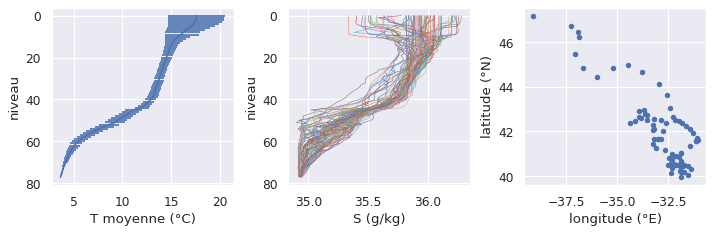

In [31]:
# ===== EXERCICE 1.3 — Profils Argo : T, S, P ont la shape (niveau, profil) =====
files = fetch("argo_float_data.zip", processor=pooch.Unzip())
def load(name):
    return np.load([f for f in files if f.endswith(name)][0])
T, S, P = load("/T.npy"), load("/S.npy"), load("/P.npy")
level, lat, lon = load("levels.npy"), load("lat.npy"), load("lon.npy")
print(T.shape, S.shape, P.shape, level.shape, lat.shape, lon.shape)   # T,S,P partagent (niveaux, profils)

# 3) l'axe des niveaux est régulier : le reconstruire de deux façons
print(np.allclose(level, np.arange(level[0], level[-1] + 1)),
      np.allclose(level, np.linspace(level[0], level[-1], level.size)))

# 4) densité relative = a*S + b*Θ + c*Θ² (une seule expression vectorisée)
from gsw import CT_from_t
a, b, c = 7.718e-1, -8.44e-2, -4.561e-3
CT = CT_from_t(S, T, P)                          # (salinité, température, pression) dans cet ordre
rho_rel = a * S + b * CT + c * CT**2
print(rho_rel.shape == T.shape)

# 5-6) stats PAR NIVEAU : on moyenne SUR les profils (axis=1) ; données manquantes -> fonctions nan*
n_nan = np.isnan(T).sum()
print(n_nan, f"{100 * n_nan / T.size:.1f} % de NaN")
T_mean, T_std = np.nanmean(T, axis=1), np.nanstd(T, axis=1)
S_mean, rho_mean = np.nanmean(S, axis=1), np.nanmean(rho_rel, axis=1)
print(T_mean.shape == level.shape)               # contrôle : même shape que `level`

# 7) where + masque booléen
labels = np.where(T_mean > 10, "warm", "cold")
print(labels[:5], level[T_mean < 5][:5])

# 8) tableau résumé (4, n_niveaux) -> save / load
summary = np.vstack([level, T_mean, S_mean, rho_mean])
np.save("_files/argo_summary.npy", summary)
print(summary.shape, np.allclose(summary, np.load("_files/argo_summary.npy"), equal_nan=True))

# 9-11) figures : profil moyen ± écart-type (profondeur vers le bas), tous les profils, positions
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].errorbar(T_mean, level, xerr=T_std); axes[0].set_xlabel("T moyenne (°C)")   # barre HORIZONTALE : xerr
axes[1].plot(S, level, lw=0.5); axes[1].set_xlabel("S (g/kg)")                       # 1 ligne par colonne (profil)
for ax in axes[:2]:
    ax.set_ylabel("niveau"); ax.invert_yaxis()
axes[2].scatter(lon, lat, s=15); axes[2].set(xlabel="longitude (°E)", ylabel="latitude (°N)")
plt.tight_layout(); plt.show()

---
## 1.4 — matplotlib, cartopy, xarray

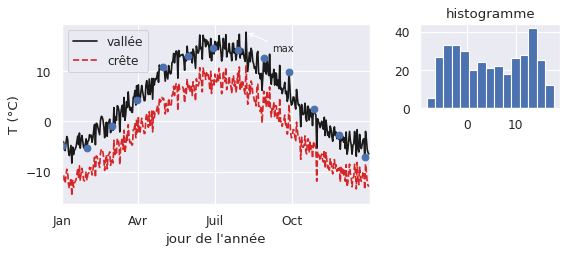

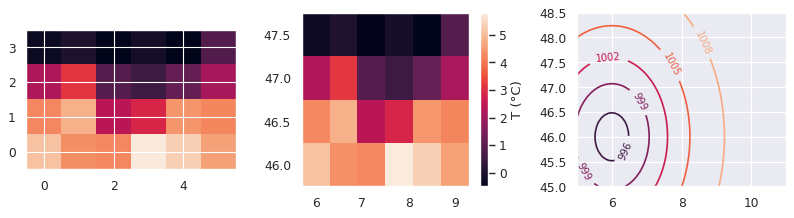

In [32]:
# 🔖 THÉORIE 1.4 — matplotlib : figure = la feuille ; axes = un graphique. Style objet : ax.plot(), ax.set_xlabel() (pas plt.plot)
rng = np.random.default_rng(0)
days = np.arange(366); valley = 5 - np.cos(2 * np.pi * days / 366) * 10 + rng.normal(0, 1.5, 366); ridge = valley - 6.5

fig = plt.figure(figsize=(7, 3))
ax_big = fig.add_axes([0.08, 0.15, 0.55, 0.75])       # add_axes([gauche, bas, largeur, hauteur]) en fractions de la figure
ax_small = fig.add_axes([0.72, 0.55, 0.25, 0.35])     # (plt.subplots(nrows, ncols) = grille régulière -> renvoie fig, axes)
ax_big.plot(days, valley, "k-", label="vallée")                                   # color / linestyle / marker / linewidth
ax_big.plot(days, ridge, color="tab:red", linestyle="--", label="crête")          # séries distinguables sans la couleur
ax_big.plot(days[::30], valley[::30], linestyle="none", marker="o")               # marqueurs sans ligne
ax_big.set(xlabel="jour de l'année", ylabel="T (°C)", xlim=(0, 366)); ax_big.legend(); ax_big.grid(True)
ax_big.set_xticks([0, 91, 182, 274]); ax_big.set_xticklabels(["Jan", "Avr", "Juil", "Oct"])   # ticks + étiquettes
ax_big.annotate("max", xy=(valley.argmax(), valley.max()), xytext=(250, 14), arrowprops={"arrowstyle": "->"})   # texte + flèche
ax_small.hist(valley, bins=15); ax_small.set_title("histogramme")                 # aussi : scatter(c=, s=), bar / barh
plt.show()

# Champs 2D : imshow (par POSITION, ignore les coordonnées, origin="upper" par défaut -> carte à l'envers !)
#             pcolormesh (avec coordonnées) | contour (lignes) / contourf (rempli) | quiver (flèches) / streamplot (lignes de courant)
lon = np.linspace(6, 9, 6); lat = np.linspace(46, 47.5, 4)                        # lat croissante : sud -> nord
field = 5 + (46 - lat)[:, None] * 3 + rng.normal(0, 1, (4, 6))
lon_f, lat_f = np.meshgrid(np.linspace(5, 11, 61), np.linspace(45, 48.5, 36))      # meshgrid : 2 axes 1D -> 2 grilles 2D
pres = 1013 - 18 / (1 + (np.hypot(lon_f - 6, lat_f - 46) / 2) ** 2)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))                                 # axes = tableau numpy
axes[0].imshow(field, origin="lower")
pc = axes[1].pcolormesh(lon, lat, field, shading="auto"); fig.colorbar(pc, ax=axes[1], label="T (°C)")   # "auto" : coord = centres
cs = axes[2].contour(lon_f, lat_f, pres, 5); axes[2].clabel(cs)
plt.tight_layout(); plt.show()
# Tout graphique : axes étiquetés (grandeur + unité), colorbar étiquetée, éviter rouge/vert et "jet", police ≥ 12 pt en présentation
# fig.savefig("f.pdf") : svg/pdf = vectoriel (net à toute taille) ; png = pixels

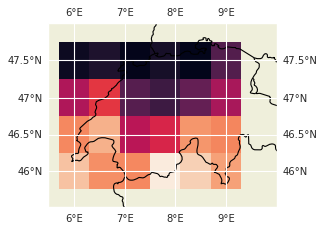

In [33]:
# 🔖 THÉORIE 1.4 — cartopy : cartes
import cartopy.crs as ccrs, cartopy.feature as cfeature
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.Mercator()})      # projection = COMMENT on dessine la carte
ax.set_extent([5.5, 10, 45.5, 48], crs=ccrs.PlateCarree())               # zone affichée, en lon/lat
ax.add_feature(cfeature.LAND); ax.add_feature(cfeature.BORDERS); ax.gridlines(draw_labels=True)
ax.pcolormesh(lon, lat, field, transform=ccrs.PlateCarree())             # transform = CRS des COORDONNÉES des données
plt.show()                                                               # (transform oublié -> rien/mauvais endroit, SANS erreur)
# PlateCarree : lon/lat brutes (modèles) | Mercator : navigation (aires déformées) | EqualEarth : aires justes (réf. générale)
# Robinson : compromis | Orthographic : globe | North/SouthPolarStereo : pôles | Spilhaus : océans = un seul bloc

['t2m']


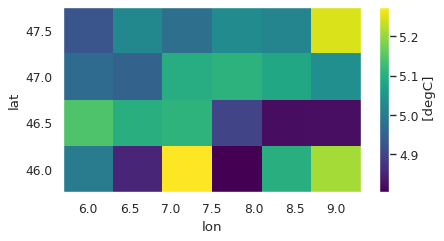

In [34]:
# 🔖 THÉORIE 1.4 — xarray : tableaux étiquetés
import xarray as xr
time = np.arange("2024-01-01", "2025-01-01", dtype="datetime64[D]")
t2m = xr.DataArray(rng.normal(5, 3, (366, 4, 6)), dims=("time", "lat", "lon"),
                   coords={"time": time, "lat": lat, "lon": lon}, attrs={"units": "degC"})
ds = xr.Dataset({"t2m": t2m})                  # DataArray = 1 tableau étiqueté (dims, coords, attrs) ; Dataset = dict de DataArray
t2m.isel(time=0)                               # sélection par POSITION  (≈ .iloc)
t2m.sel(time="2024-07-15")                     # sélection par ÉTIQUETTE (≈ .loc)
t2m.sel(lat=46.7, method="nearest")            # étiquette la plus proche
serie = t2m.mean(dim=("lat", "lon"))           # réduction par NOM de dimension -> série temporelle (pas de axis=0 !)
anom = t2m - t2m.mean(dim="time")              # arithmétique alignée sur les coordonnées
mensuel = t2m.resample(time="MS").mean()       # ré-échantillonnage par période (MS = début de mois)
clim = t2m.groupby("time.month").mean()        # regroupe par mois civil (12 valeurs)
t2m.mean(dim="time").plot()                    # .plot() lit coordonnées + unités ; 1D -> ligne, 2D -> pcolormesh
ds.to_netcdf("_files/t.nc"); print(list(xr.open_dataset("_files/t.nc").data_vars))   # netCDF garde coords + attrs

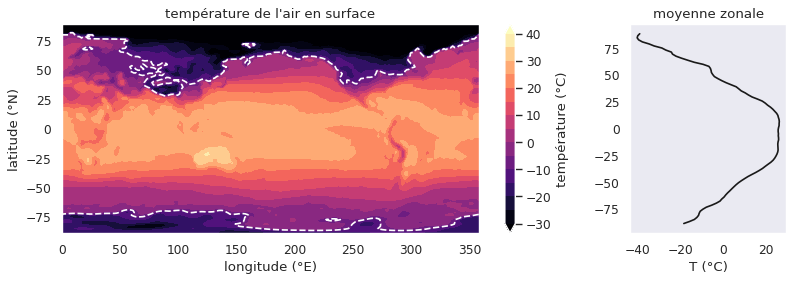

moyenne zonale la plus froide : -40 °C à 85° N


In [35]:
# ===== EXERCICE 1.4-A — contourf + moyenne zonale (NCEP, température de surface) =====
lon = np.load(fetch("ncep_global_temp_lon.npy")); lat = np.load(fetch("ncep_global_temp_lat.npy"))
temp_c = np.load(fetch("ncep_global_temp_kelvin.npy")) - 273.15       # K -> °C ; shape (94, 192) = (lat, lon)

fig, (ax_map, ax_mean) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [5, 1.5]})
cf = ax_map.contourf(lon, lat, temp_c, levels=np.linspace(-30, 40, 15), cmap="magma", extend="both")
ax_map.contour(lon, lat, temp_c, levels=[-10], colors="w")            # une seule isoligne à -10 °C
fig.colorbar(cf, ax=ax_map, label="température (°C)")
ax_map.set(title="température de l'air en surface", xlabel="longitude (°E)", ylabel="latitude (°N)")
ax_mean.plot(np.nanmean(temp_c, axis=1), lat, "k")                    # moyenne zonale = moyenne sur la longitude (axis=1)
ax_mean.set(title="moyenne zonale", xlabel="T (°C)"); ax_mean.grid()
plt.tight_layout(); plt.show()
zonal = np.nanmean(temp_c, axis=1)
print("moyenne zonale la plus froide :", f"{zonal.min():.0f} °C à {lat[zonal.argmin()]:.0f}° N")
# Hiver BORÉAL : minimum au pôle Nord (≈ -40 °C) alors que le pôle Sud est moins froid (≈ -18 °C)

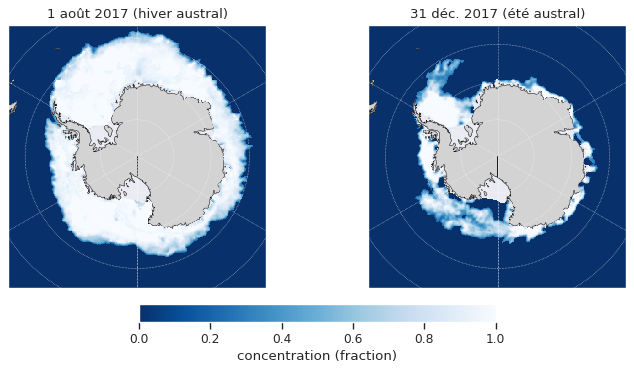

In [36]:
# ===== EXERCICE 1.4-B — Glace de mer antarctique : xarray + cartopy =====
import cartopy.crs as ccrs, cartopy.feature as cfeature
import xarray as xr
paths = {"1 août 2017 (hiver austral)": fetch("seaice_conc_daily_sh_f17_20170801_v03r01.nc"),
         "31 déc. 2017 (été austral)": fetch("seaice_conc_daily_sh_f17_20171231_v03r01.nc")}
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), constrained_layout=True,
                         subplot_kw={"projection": ccrs.SouthPolarStereo()})
for ax, (title, path) in zip(axes, paths.items()):
    ds = xr.open_dataset(path).isel(time=0)                        # un seul pas de temps
    conc = ds["seaice_conc_cdr"].where(ds["seaice_conc_cdr"] <= 1) # valeurs > 1 = codes (terre, manquant) -> NaN
    pcm = ax.pcolormesh(ds["longitude"], ds["latitude"], conc, transform=ccrs.PlateCarree(),   # lon/lat 2D -> pas .plot()
                        vmin=0, vmax=1, cmap="Blues_r")                                         # même échelle -> 1 colorbar
    ax.set_extent([-180, 180, -90, -55], ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="lightgrey", edgecolor="k", linewidth=0.5)
    ax.gridlines(linewidth=0.5, linestyle=":"); ax.set_title(title)
fig.colorbar(pcm, ax=axes, orientation="horizontal", shrink=0.5, label="concentration (fraction)")
plt.show()                                                          # plus de glace en août (hiver austral)

In [37]:
# ===== EXERCICE 1.4-C — Anomalies mensuelles : resample vs groupby =====
rng = np.random.default_rng(0)
time = np.arange("2024-01-01", "2025-01-01", dtype="datetime64[D]"); n = time.size
t = 5 - np.cos(2 * np.pi * np.arange(n) / n) * 10 + rng.normal(0, 1.5, n)
da = xr.DataArray(t, dims="time", coords={"time": time}, attrs={"units": "degC"})
anom = da - da.mean()                                              # anomalie = valeur - moyenne annuelle
m1 = anom.resample(time="MS").mean()                               # 12 valeurs indexées par DATE
m2 = anom.groupby("time.month").mean()                             # 12 valeurs indexées par N° de mois
print("mois le plus chaud :", int(m2.idxmax("month")), "| écart max entre les deux :", float(abs(m1.values - m2.values).max()))
# Sur 10 ans : resample -> 120 valeurs (une par mois réel) ; groupby("time.month") -> 12 valeurs (tous les janviers mélangés)

mois le plus chaud : 7 | écart max entre les deux : 0.0


---
## 1.5 — pandas

<class 'pandas.core.frame.DataFrame'>
Index: 3 entries, Mercure to Terre
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   mass    3 non-null      float64
 1   diam    3 non-null      int64  
 2   dens    3 non-null      float64
 3   classe  1 non-null      object 
dtypes: float64(2), int64(1), object(1)
memory usage: 228.0+ bytes
       mass     diam  dens
count   3.0      3.0   3.0
mean    3.7   9913.0   0.0
std     3.0   4371.7   0.0
min     0.3   4879.0   0.0
25%     2.6   8491.5   0.0
50%     4.9  12104.0   0.0
75%     5.4  12430.0   0.0
max     6.0  12756.0   0.0
2


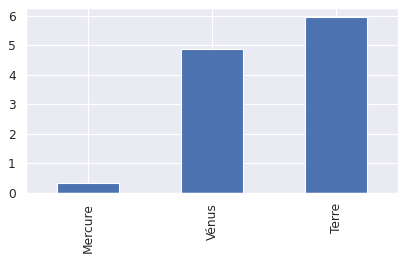

In [38]:
# 🔖 THÉORIE 1.5
# Series = tableau 1D étiqueté | DataFrame = colonnes (Series) partageant UN index, chacune avec son dtype
df = pd.DataFrame({"mass": [0.33, 4.87, 5.97], "diam": [4879, 12104, 12756]}, index=["Mercure", "Vénus", "Terre"])
df.loc["Terre", "mass"]; df.iloc[2, 0]            # loc = ÉTIQUETTES (tranche : fin INCLUSE) | iloc = POSITIONS (fin exclue)
df[(df["mass"] > 1) & (df["diam"] > 12500)]       # filtre : & | ~ (pas and/or/not) et parenthèses autour de chaque condition
df["dens"] = df["mass"] / df["diam"] ** 3         # nouvelle colonne, sans boucle
df.loc[df["mass"] > 5, "classe"] = "grosse"       # modification par masque (autres lignes = NaN)
s = pd.Series([1, 2], index=["a", "b"]); s.values; s.index        # .values -> numpy ; .index -> étiquettes
# combiner : a.join(b) (sur l'INDEX) | a.merge(b, on="col") (sur une COLONNE) | pd.concat([a, b]) (empile) ; absent d'un côté -> NaN
df.info(); print(df.describe().round(1)); print(df.isna().sum().sum())    # structure / stats (ignorent NaN) / nb de manquants
df["mass"].plot(kind="bar"); plt.show()                           # .plot() = matplotlib ; kind = line, bar, hist, scatter, box

In [39]:
# 🔖 THÉORIE 1.5 (suite) — séries temporelles : lecture robuste, resample, rolling, groupby, NaN
station = pd.read_csv(fetch("uscrn_daily_2017_ny_millbrook_3w.txt"), sep=r"\s+",    # séparateur = espaces multiples
                      na_values=[-9999.0, -99.0],                                  # codes "manquant" -> NaN
                      parse_dates=["LST_DATE"], date_format="%Y%m%d",              # entiers -> datetime64
                      dtype={"WBANNO": "string"}).set_index("LST_DATE")            # identifiant = texte ; date = index
print(station.loc["2017-07-01":"2017-07-03", "T_DAILY_MEAN"].round(1).tolist())    # tranche de dates (index datetime)
mensuel = station["T_DAILY_MEAN"].resample("MS").mean()                            # ré-échantillonnage ("MS" = début de mois)
glissant = station["T_DAILY_MEAN"].rolling(window=7).mean()                        # moyenne glissante (window-1 premiers = NaN)
resume = station.groupby(station.index.month).agg(                                 # groupby = split -> apply -> combine
    mean_temp=("T_DAILY_MEAN", "mean"), total_precip=("P_DAILY_CALC", "sum"), n_days=("T_DAILY_MEAN", "size"))
print("mois le plus chaud :", resume["mean_temp"].idxmax())                        # idxmax = ÉTIQUETTE du maximum
sol = station["SOIL_MOISTURE_5_DAILY"]
print(sol.isna().sum(), round(sol.mean(), 3), round(sol.fillna(0).mean(), 3))      # ⚠️ manquant ≠ zéro : fillna(0) biaise la moyenne
# remplir un trou = choix physique : ffill (dernière valeur) ou interpolate (droite entre voisins) ; les stats ignorent déjà NaN
resume.to_csv("_files/resume.csv")                                                 # écriture avec un chemin pathlib

[23.9, 24.1, 21.7]
mois le plus chaud : 7
48 0.189 0.165


<class 'pandas.core.frame.DataFrame'>
Index: 120108 entries, ak11155107 to ak11453389
Data columns (total 14 columns):
 #   Column     Non-Null Count   Dtype              
---  ------     --------------   -----              
 0   time       120108 non-null  datetime64[ns]     
 1   latitude   120108 non-null  float64            
 2   longitude  120108 non-null  float64            
 3   depth      120107 non-null  float64            
 4   mag        120065 non-null  float64            
 5   magType    120065 non-null  object             
 6   nst        59688 non-null   float64            
 7   gap        94935 non-null   float64            
 8   dmin       85682 non-null   float64            
 9   rms        119716 non-null  float64            
 10  net        120108 non-null  object             
 11  updated    120108 non-null  datetime64[ns, UTC]
 12  place      120108 non-null  object             
 13  type       120108 non-null  object             
dtypes: datetime64[ns, UTC](1), d

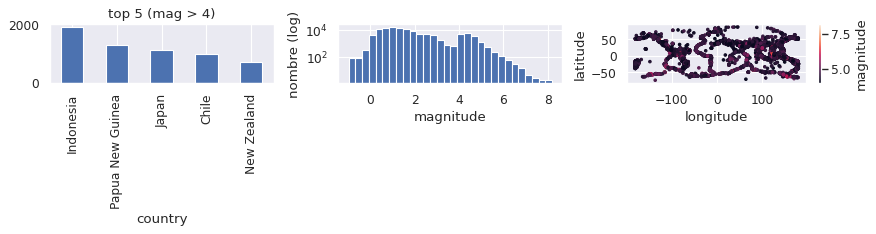

In [40]:
# ===== EXERCICE 1.5 — Séismes USGS 2014 : CSV -> dates -> filtre -> texte -> graphes =====
eq = pd.read_csv(fetch("usgs_earthquakes_2014.csv"),
                 parse_dates=["time", "updated"], index_col="id")            # colonnes de dates + index = id
eq.info()
print(eq.describe().loc[["count", "mean", "max"], ["mag", "depth"]])
print(eq.nlargest(5, "mag")[["place", "mag"]])                               # les 5 plus grosses magnitudes
eq["country"] = eq["place"].str.split(", ").str[-1]                          # texte : "26km S of X, Alaska" -> "Alaska"
print(eq["country"].nunique(), "pays/États distincts ; ex. :", eq["country"].unique()[:4])
big = eq[eq["mag"] > 4]                                                      # filtre booléen
print("nb séismes mag > 4 :", big["mag"].count())                           # count ignore les NaN
top5 = big["country"].value_counts().head(5)                                 # nombre par pays, trié

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
top5.plot(kind="bar", ax=axes[0], title="top 5 (mag > 4)")
axes[1].hist(eq["mag"], bins=30); axes[1].set_yscale("log")                  # axe y log : voir les rares gros séismes
axes[1].set(xlabel="magnitude", ylabel="nombre (log)")
sc = axes[2].scatter(big["longitude"], big["latitude"], c=big["mag"], s=5)   # c = couleur = 3e variable
fig.colorbar(sc, ax=axes[2], label="magnitude"); axes[2].set(xlabel="longitude", ylabel="latitude")
plt.tight_layout(); plt.show()

---
## 1.6 — geopandas (données vectorielles)

In [41]:
# 🔖 THÉORIE 1.6
import geopandas as gpd
from shapely.geometry import Point, Polygon
st = pd.DataFrame({"name": ["Basel", "Zurich", "Bern"], "lon": [7.59, 8.54, 7.44], "lat": [47.56, 47.37, 46.95]})
stations = gpd.GeoDataFrame(st, geometry=gpd.points_from_xy(st["lon"], st["lat"]), crs="EPSG:4326")   # DataFrame + colonne geometry + CRS
# Types shapely : Point | LineString (LinearRing = fermée) | Polygon + versions Multi… ; chacun a intérieur / frontière / extérieur
zones = gpd.GeoDataFrame({"zone": ["A"]}, crs="EPSG:2056",
        geometry=[Polygon([(2.59e6, 1.23e6), (2.65e6, 1.23e6), (2.65e6, 1.29e6), (2.59e6, 1.29e6)])])
# E/S : gpd.read_file("f.gpkg") ; gdf.to_file("f.gpkg", driver="GPKG") ; aussi .shp (plusieurs fichiers, limites) et .geojson -> préférer gpkg
st_m = stations.to_crs(2056)                     # reprojection : EPSG:4326 = WGS84 (DEGRÉS) | EPSG:2056 = LV95 suisse (MÈTRES)
print(st_m.crs.to_epsg(), stations.crs.to_epsg())                 # .crs lit le CRS
# ⚠️ area / length / distance / buffer : TOUJOURS dans un CRS métrique (en degrés le résultat n'a aucun sens physique)
print(round(st_m.geometry.iloc[0].distance(st_m.geometry.iloc[2]) / 1000, 1), "km Bâle-Berne")
print(zones.area.iloc[0] / 1e6, "km² |", zones.length.iloc[0] / 1e3, "km |", zones.centroid.iloc[0])   # aire, périmètre, centre
buf = st_m.buffer(40_000)                        # zone tampon de 40 km (unités du CRS = mètres)
print(round(buf.union_all().area / 1e6), "km² (union : les recouvrements comptent 1 fois)")
print(gpd.sjoin(st_m, zones, predicate="within")["name"].tolist())                  # jointure spatiale (même CRS exigé !)
# autres : convex_hull | envelope | dissolve(by="col") (fusion par attribut) | overlay(a, b, how="intersection") | .boundary
# prédicats : within, contains, intersects ; .isin(liste) pour filtrer par valeurs

2056 4326
68.8 km Bâle-Berne
3600.0 km² | 240.0 km | POINT (2620000 1260000)
14647 km² (union : les recouvrements comptent 1 fois)
['Basel']


['MultiPolygon', 'Polygon']
True
['Kentucky', 'Massachusetts', 'North Carolina', 'Pennsylvania', 'South Carolina', 'Virginia', 'West Virginia']


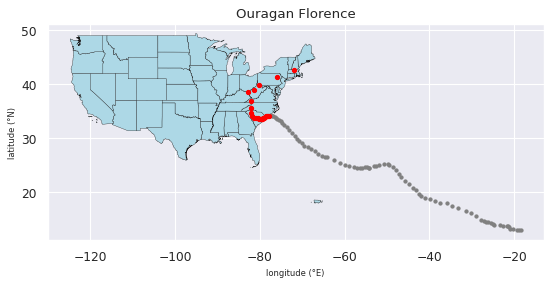

In [42]:
# ===== EXERCICE 1.6 — Quels États l'ouragan Florence a-t-il traversés ? =====
states = gpd.read_file(fetch("gz_2010_us_040_00_5m.json"))                   # polygones des États
states = states[~states["NAME"].isin(["Alaska", "Hawaii"])]                  # ~ = NON ; isin(liste)
print(states.geom_type.unique().tolist())                                    # Polygon et MultiPolygon

fl = pd.read_csv(fetch("florence.csv")).drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)
fl["Long"] = -fl["Long"]                                                     # longitude Ouest stockée en positif -> signe -
gdf = gpd.GeoDataFrame(fl, geometry=gpd.points_from_xy(fl["Long"], fl["Lat"]), crs="EPSG:4326")
print(states.crs == gdf.crs)                                                 # même CRS -> les couches se superposent

inside = gpd.overlay(gdf, states, how="intersection")                        # points de la trajectoire DANS un État
print(sorted(inside["NAME"].unique()))                                       # <- réponse

fig, ax = plt.subplots(figsize=(8, 5))
states.plot(ax=ax, color="lightblue", edgecolor="k", linewidth=0.3)          # fond de carte
gdf.plot(ax=ax, color="grey", markersize=8)                                  # trajectoire complète
inside.plot(ax=ax, color="red", markersize=14)                               # partie sur les États-Unis
ax.set(xlabel="longitude (°E)", ylabel="latitude (°N)", title="Ouragan Florence"); plt.show()

---
## 1.7 — Programmation orientée objet et défensive

In [43]:
# 🔖 THÉORIE 1.7
from dataclasses import dataclass
import logging

class WeatherStation:
    lapse_rate = -6.5                        # attribut de CLASSE : partagé -> OK pour une constante, JAMAIS pour une liste/dict
    def __init__(self, name: str, elevation_m: float):          # constructeur ; self = l'instance courante
        if not -430 <= elevation_m <= 8849:
            raise ValueError(f"altitude impossible : {elevation_m} m")   # valider À LA CONSTRUCTION
        self.name, self.elevation_m = name, elevation_m          # attributs d'INSTANCE (propres à l'objet)
        self.readings_celsius: list[float] = []                  # liste créée DANS __init__ -> une par objet
    def add_reading(self, t: float) -> None:                     # méthode qui MODIFIE l'état
        self.readings_celsius.append(t)
    def mean_temperature(self) -> float:                         # méthode qui LIT l'état
        return sum(self.readings_celsius) / len(self.readings_celsius)
    def __repr__(self) -> str:                                   # méthode dunder : appelée par print()
        return f"WeatherStation({self.name!r}, {self.elevation_m} m)"

class RiverGauge(WeatherStation):                                # héritage = relation « est un »
    def __init__(self, name, elevation_m):
        super().__init__(name, elevation_m)                      # réutilise le constructeur du parent
        self.discharge_m3s = []                                  # + état propre à la sous-classe

class StationNetwork:                                            # composition = relation « a un » (préférable à l'héritage profond)
    def __init__(self): self.stations = {}                       # le réseau DÉLÈGUE aux stations qu'il contient

@dataclass                                                       # génère __init__, __repr__, __eq__ pour un simple enregistrement
class Reading:
    timestamp: str
    temp_celsius: float

jfj = WeatherStation("Jungfraujoch", 3571); jfj.add_reading(-2.3); print(jfj, Reading("t0", 1.0) == Reading("t0", 1.0))
# Classe seulement s'il y a un ÉTAT à conserver ; calcul sans état (°C -> K) = simple fonction

# --- code défensif ---
class PhysicalRangeError(ValueError): pass                       # exception personnalisée (plus précise qu'un ValueError)
def to_kelvin(t):
    if t < -273.15:
        raise PhysicalRangeError(f"{t} °C < zéro absolu")        # entrée EXTERNE (fichier, utilisateur) -> exception
    k = t + 273.15
    assert k >= 0, "invariant interne violé"                     # assert = invariant du CODE lui-même ; supprimé par python -O
    return k
for v in [25.0, -300.0]:
    try:
        k = to_kelvin(v)
    except PhysicalRangeError as err:                            # except : gère l'erreur
        print("rejeté :", err)
    else:
        print("ok", k)                                           # else : seulement si AUCUNE exception
    finally:
        print("vérifié", v)                                      # finally : TOUJOURS exécuté
logging.basicConfig(level=logging.INFO, force=True)              # logging > print : niveaux DEBUG < INFO < WARNING < ERROR
logging.getLogger("demo").info("chargé 45 mesures"); logging.getLogger("demo").debug("masqué (sous le seuil INFO)")
logging.getLogger().setLevel(logging.WARNING)                    # (on remet le niveau par défaut pour la suite)
# pytest : fonctions test_* ; `assert x == y` ; pytest.approx(y) (floats) ; with pytest.raises(ValueError): ...
#          @pytest.fixture (préparation réutilisable) ; @pytest.mark.parametrize("a,b", [(0, 273.15), (25, 298.15)])
# ⚠️ `readings = []` écrit dans le CORPS de la classe = une seule liste partagée par toutes les instances

INFO:demo:chargé 45 mesures


WeatherStation('Jungfraujoch', 3571 m) True
ok 298.15
vérifié 25.0
rejeté : -300.0 °C < zéro absolu
vérifié -300.0


In [44]:
# ===== EXERCICE 1.7 — Séismes validés : classe + exceptions + pandas (corrigé à partir de la théorie) =====
quakes = pd.read_csv(fetch("usgs_earthquakes_2023_01.csv"))[["place", "mag", "depth"]]
print(quakes.shape)

class EarthquakeEvent:
    def __init__(self, place: str, magnitude: float, depth_km: float) -> None:
        if magnitude < 0.0 or depth_km < 0.0:             # donnée EXTERNE -> exception (pas assert)
            raise ValueError(f"valeur négative : mag={magnitude}, depth={depth_km}")
        self.place, self.magnitude, self.depth_km = place, magnitude, depth_km
    def is_shallow(self, threshold_km: float = 70.0) -> bool:      # valeur par défaut + type de retour
        return self.depth_km < threshold_km
    def __repr__(self) -> str:
        return f"EarthquakeEvent({self.place!r}, M{self.magnitude}, {self.depth_km} km)"

# 3) la validation fonctionne
print(EarthquakeEvent("test", 5.0, 10.0))
try:
    EarthquakeEvent("test", -1.0, 10.0)
except ValueError as err:
    print("refusé :", err)

# 4) on ajoute 2 lignes corrompues exprès, on construit un objet par ligne sans jamais s'arrêter
bad_rows = pd.DataFrame({"place": ["typo", "typo"], "mag": [-4.5, 4.5], "depth": [10.0, -35.0]})
quakes = pd.concat([quakes, bad_rows], ignore_index=True)
events, n_rejected = [], 0
for place, mag, depth in zip(quakes["place"], quakes["mag"], quakes["depth"]):
    try:
        events.append(EarthquakeEvent(place, mag, depth))
    except ValueError:
        n_rejected += 1                                   # on compte le rejet, la boucle continue

# 5) nb d'événements superficiels (True compte pour 1) + le plus profond (boucle "meilleur jusqu'ici", sans max())
n_shallow = sum(e.is_shallow() for e in events)
deepest = None
for e in events:
    if deepest is None or e.depth_km > deepest.depth_km:
        deepest = e

# 6) bilan
print(len(events), "événements,", n_rejected, "rejetés,", n_shallow, "superficiels")
print(deepest)

(629, 3)
EarthquakeEvent('test', M5.0, 10.0 km)
refusé : valeur négative : mag=-1.0, depth=10.0
629 événements, 2 rejetés, 491 superficiels
EarthquakeEvent('75 km ENE of Levuka, Fiji', M4.5, 617.888 km)


---
## 1.8 — Statistiques, machine learning (scikit-learn), seaborn

In [45]:
# 🔖 THÉORIE 1.8 — scikit-learn : interface UNIQUE  modèle = Classe()  ->  .fit(X, y)  ->  .predict(X_nouveau)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score, silhouette_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
# X = 2D (n_échantillons, n_variables) -> df[["col"]] avec DOUBLES crochets ; y = 1D.  Paramètres appris = attributs en « _ » :
#   coef_, intercept_ (régression) | labels_, cluster_centers_, inertia_ (k-means) | explained_variance_ratio_ (PCA)
# 3 piliers : RÉGRESSION (cible continue) | CLUSTERING (aucune cible) | CLASSIFICATION (cible catégorielle)
# Régression : minimise la somme des carrés des erreurs ; ŷ = w·x + b (ex. gradient thermique ≈ -6.5 °C/km)
# ÉVALUER sur des données NON vues : train_test_split(X, y, test_size=0.3, random_state=0) ; RMSE (unité de la cible) ; R² (part de variance expliquée)
# ⚠️ Surapprentissage : score train très élevé, score test mauvais -> un score d'entraînement n'est JAMAIS une performance
# StandardScaler : (x - moyenne) / écart-type ; Pipeline = le scaler est ajusté sur le TRAIN seul (pas de fuite d'information)
# KMeans : assigne chaque point au centroïde le plus proche, déplace les centroïdes, répète. Choix de k :
#   coude = inertie (diminue toujours, on cherche le « coude ») | silhouette = (b - a)/max(a, b), le MAXIMUM gagne
#   (≠ nombre d'espèces réel : on ne regroupe que dans les variables fournies)
# PCA : nouveaux axes = combinaisons linéaires ordonnées par variance ; toujours standardiser avant (sinon la grande échelle domine)
# seaborn = couche au-dessus de matplotlib : on passe data=, x=, y=, hue= (noms de colonnes) ; compatible avec ax=
rng = np.random.default_rng(0); elev = rng.uniform(200, 3500, 80); temp = 15 - 6.5 * elev / 1000 + rng.normal(0, 1.5, 80)
m = LinearRegression().fit(elev.reshape(-1, 1), temp); print("gradient retrouvé :", round(m.coef_[0] * 1000, 2), "°C/km")

gradient retrouvé : -6.67 °C/km


In [46]:
# ===== EXERCICE 1.8-A — Régression multiple (Advertising) : train/test, RMSE, R² =====
ad = pd.read_csv(fetch("Advertising.csv"))
X, y = ad[["TV", "Radio", "Newspaper"]], ad["Sales"]                       # X 2D (3 colonnes), y 1D
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0)
model = LinearRegression().fit(X_tr, y_tr)
print(dict(zip(X.columns, model.coef_.round(3).tolist())), "| intercept :", round(model.intercept_, 2))
pred = model.predict(X_te)
print("RMSE test :", round(root_mean_squared_error(y_te, pred), 2), "| R² test :", round(r2_score(y_te, pred), 3))
# Comparer les coefficients n'a de sens que si les colonnes ont la même échelle -> standardiser d'abord :
pipe = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
print("coefficients standardisés :", dict(zip(X.columns, pipe[-1].coef_.round(2).tolist())), "| R² :", round(pipe.score(X_te, y_te), 3))

{'TV': 0.044, 'Radio': 0.2, 'Newspaper': 0.002} | intercept : 2.88
RMSE test : 1.92 | R² test : 0.865
coefficients standardisés : {'TV': 3.68, 'Radio': 3.05, 'Newspaper': 0.04} | R² : 0.865


(342, 8)
cluster      0   1    2
species                
Adelie       2  38  111
Chinstrap    5  54    9
Gentoo     122   1    0


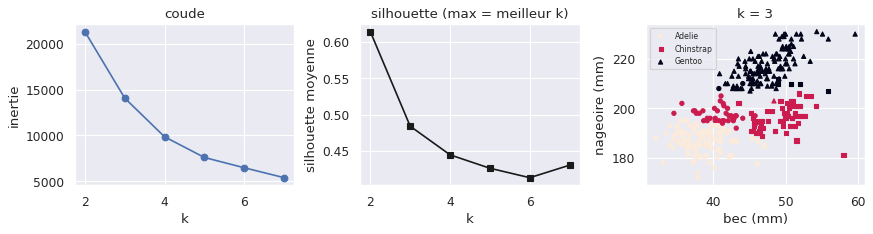

variance expliquée : [0.688 0.193]
précision (test) : 0.97 | poids : {'bill_length_mm': 3.79, 'bill_depth_mm': -1.19}


In [47]:
# ===== EXERCICE 1.8-B — Manchots : k-means (coude + silhouette), PCA, classification =====
peng = pd.read_csv(fetch("palmer_penguins.csv")).dropna(
    subset=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]).reset_index(drop=True)
print(peng.shape)                                                          # (342, ...)

# --- clustering : combien de groupes ? ---
Xc = peng[["bill_length_mm", "flipper_length_mm"]]
ks = list(range(2, 8))
inertia = [KMeans(k, random_state=0, n_init=10).fit(Xc).inertia_ for k in ks]                       # coude
sil = [silhouette_score(Xc, KMeans(k, random_state=0, n_init=10).fit_predict(Xc)) for k in ks]    # silhouette
km = KMeans(n_clusters=3, random_state=0, n_init=10).fit(Xc)
peng["cluster"] = km.labels_
print(pd.crosstab(peng["species"], peng["cluster"]))                        # clusters trouvés vs vraies espèces

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].plot(ks, inertia, "o-"); axes[0].set(xlabel="k", ylabel="inertie", title="coude")
axes[1].plot(ks, sil, "s-k"); axes[1].set(xlabel="k", ylabel="silhouette moyenne", title="silhouette (max = meilleur k)")
for sp, g in peng.groupby("species"):                                       # forme = vraie espèce, couleur = cluster
    axes[2].scatter(g["bill_length_mm"], g["flipper_length_mm"], c=g["cluster"], vmin=0, vmax=2, s=14, label=sp,
                    marker={"Adelie": "o", "Chinstrap": "s", "Gentoo": "^"}[sp])
axes[2].legend(fontsize=7); axes[2].set(xlabel="bec (mm)", ylabel="nageoire (mm)", title="k = 3")
plt.tight_layout(); plt.show()

# --- PCA : 4 mesures standardisées -> 2 composantes ---
feats = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
pca = PCA(n_components=2).fit(StandardScaler().fit_transform(peng[feats]))
print("variance expliquée :", pca.explained_variance_ratio_.round(3))

# --- classification : Adélie vs Chinstrap à partir du bec seul ---
two = peng[peng["species"].isin(["Adelie", "Chinstrap"])]
Xb, yb = two[["bill_length_mm", "bill_depth_mm"]], two["species"]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=0, stratify=yb)   # stratify : mêmes proportions
clf = make_pipeline(StandardScaler(), LogisticRegression()).fit(Xb_tr, yb_tr)
print("précision (test) :", round(clf.score(Xb_te, yb_te), 3), "| poids :", dict(zip(Xb.columns, clf[-1].coef_[0].round(2).tolist())))

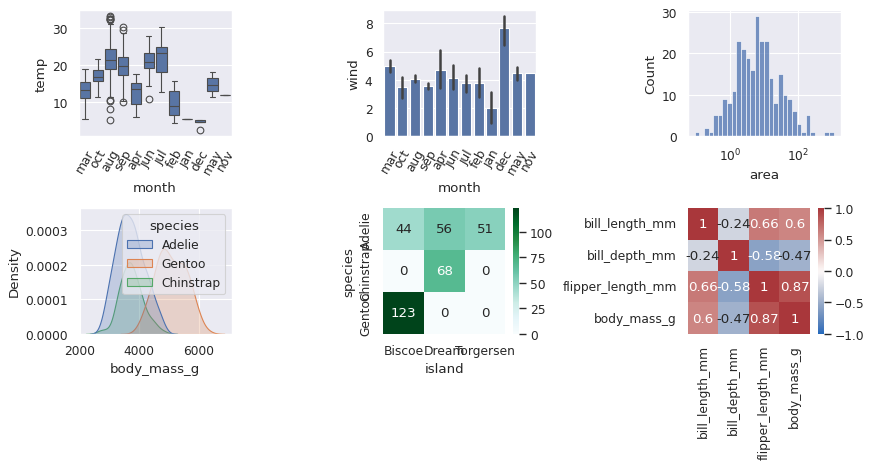

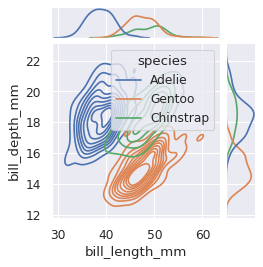

In [48]:
# ===== EXERCICE 1.8-C — seaborn : distributions, catégories, corrélations =====
import seaborn as sns
sns.set_theme()                                                             # style seaborn pour toutes les figures suivantes
ff = pd.read_csv(fetch("forest_fires.csv"))
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
sns.boxplot(data=ff, x="month", y="temp", ax=axes[0, 0])                    # médiane, quartiles, outliers par catégorie
sns.barplot(data=ff, x="month", y="wind", ax=axes[0, 1])                    # moyenne par catégorie (+ barre d'erreur)
sns.histplot(ff.loc[ff["area"] > 0, "area"], bins=30, ax=axes[0, 2], log_scale=True)   # on retire les surfaces nulles (très asymétrique)
sns.kdeplot(data=peng, x="body_mass_g", hue="species", fill=True, ax=axes[1, 0])       # hue= un groupe par couleur ; cut=0 si variable bornée
sns.heatmap(pd.crosstab(peng["species"], peng["island"]), annot=True, fmt="d", cmap="BuGn", ax=axes[1, 1])   # tableau croisé
sns.heatmap(peng[feats].corr().round(2), annot=True, cmap="vlag", vmin=-1, vmax=1, ax=axes[1, 2])           # corrélations
for ax in axes[0, :2]: ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
# kdeplot : bw_adjust = lissage ; common_norm=False compare les FORMES | jointplot(kind="kde"/"hex") = 2D + densités marginales
# displot(col=) / FacetGrid = un panneau par catégorie | catplot(kind="box"/"count"/"violin") | regplot = droite + bande de confiance
sns.jointplot(data=peng, x="bill_length_mm", y="bill_depth_mm", hue="species", kind="kde", height=3.5); plt.show()

---
## 🔖 Pièges classiques (souvent en QCM)
| Leçon | Piège → réflexe |
|---|---|
| 1.1 | `"-8.4" > "-9.2"` est `False` (str comparés caractère par caractère) → `float()` avant de comparer · `int()` tronque, `round()` va à la paire · jamais `==` sur des floats (`math.isclose`) · `"w"` écrase, `"a"` ajoute |
| 1.2 | argument par défaut mutable `out=[]` partagé entre appels → `out=None` · `list` mutable / `tuple` immuable · `.get(clé, défaut)` · `break` sort, `continue` saute le tour |
| 1.3 | tranche = **vue** (`.copy()`) · broadcasting aligné sur la **dernière** dimension (`[:, None]`) · `nan` se propage (`nanmean`) · `zeros_like(int)` tronque · `arange` exclut la fin, `linspace` l'inclut |
| 1.4 | `imshow` ignore les coordonnées et part de `origin="upper"` → carte à l'envers · `transform=` oublié → rien sur la carte, sans erreur · `plt.subplots` + `ax.` plutôt que `plt.` · rouge/vert, `jet` à éviter · figures de présentation en svg/pdf |
| 1.5 | `.loc` fin **incluse**, `.iloc` fin exclue · `&` `\|` `~` avec parenthèses · `na_values` pour les codes −9999 · `fillna(0)` invente des mesures · `join` (index) / `merge` (colonne) / `concat` (empile) |
| 1.6 | mesurer en degrés n'a aucun sens → `to_crs(2056)` avant `area` / `distance` / `buffer` · deux couches doivent avoir le même CRS · `sjoin` / `overlay` relient par la position |
| 1.7 | liste écrite dans le corps de la classe = partagée par toutes les instances → dans `__init__` · `assert` = invariants internes, **exceptions** = entrées externes · calcul sans état → fonction, pas classe · `else` (aucune erreur) / `finally` (toujours) |
| 1.8 | score d'**entraînement** ≠ performance → toujours un jeu de test · scaler dans un `Pipeline` (pas de fuite) · silhouette max ≠ nombre réel d'espèces · corrélation sur données mélangées peut s'inverser dans chaque groupe · X en 2D (`df[["col"]]`) |